# Plotly Dash - site and payload interactions

In [1]:
from pathlib import Path
import sys, json, pandas as pd
root = Path.cwd()
if not (root / 'src').exists(): root = root.parent
sys.path.insert(0, str(root / 'src'))
from IPython.display import display, Image, IFrame


In [2]:
from dash_app import app,update,DATA
client=app.server.test_client()
assert client.get('/').status_code==200
assert client.get('/_dash-layout').status_code==200
for site,payload in [('All',[0,10000]),('KSC LC-39A',[0,10000]),('All',[2000,6000])]:
    pie,scatter,caption=update(site,payload)
    print(site,caption)
    print('Pie values:',list(pie.data[0].values))
print('Interactive app: python src/dash_app.py')

All Scatter: 56 records in payload range 0-10,000 kg. Pie chart uses all payloads at the selected site.
Pie values: [np.int64(7), np.int64(3), np.int64(10), np.int64(4)]
KSC LC-39A Scatter: 13 records in payload range 0-10,000 kg. Pie chart uses all payloads at the selected site.
Pie values: [np.int64(10), np.int64(3)]
All Scatter: 34 records in payload range 2,000-6,000 kg. Pie chart uses all payloads at the selected site.
Pie values: [np.int64(7), np.int64(3), np.int64(10), np.int64(4)]
Interactive app: python src/dash_app.py


In [3]:
display(DATA.groupby('Launch Site')['class'].agg(['count','sum','mean']))
display(DATA.groupby('Booster Version Category')['class'].agg(['count','sum','mean']))

,count,sum,mean
Launch Site,,,
CCAFS LC-40,26,7,0.269231
CCAFS SLC-40,7,3,0.428571
KSC LC-39A,13,10,0.769231
VAFB SLC-4E,10,4,0.400000


,count,sum,mean
Booster Version Category,,,
B4,11,6,0.545455
B5,1,1,1.000000
FT,24,16,0.666667
v1.0,5,0,0.000000
v1.1,15,1,0.066667


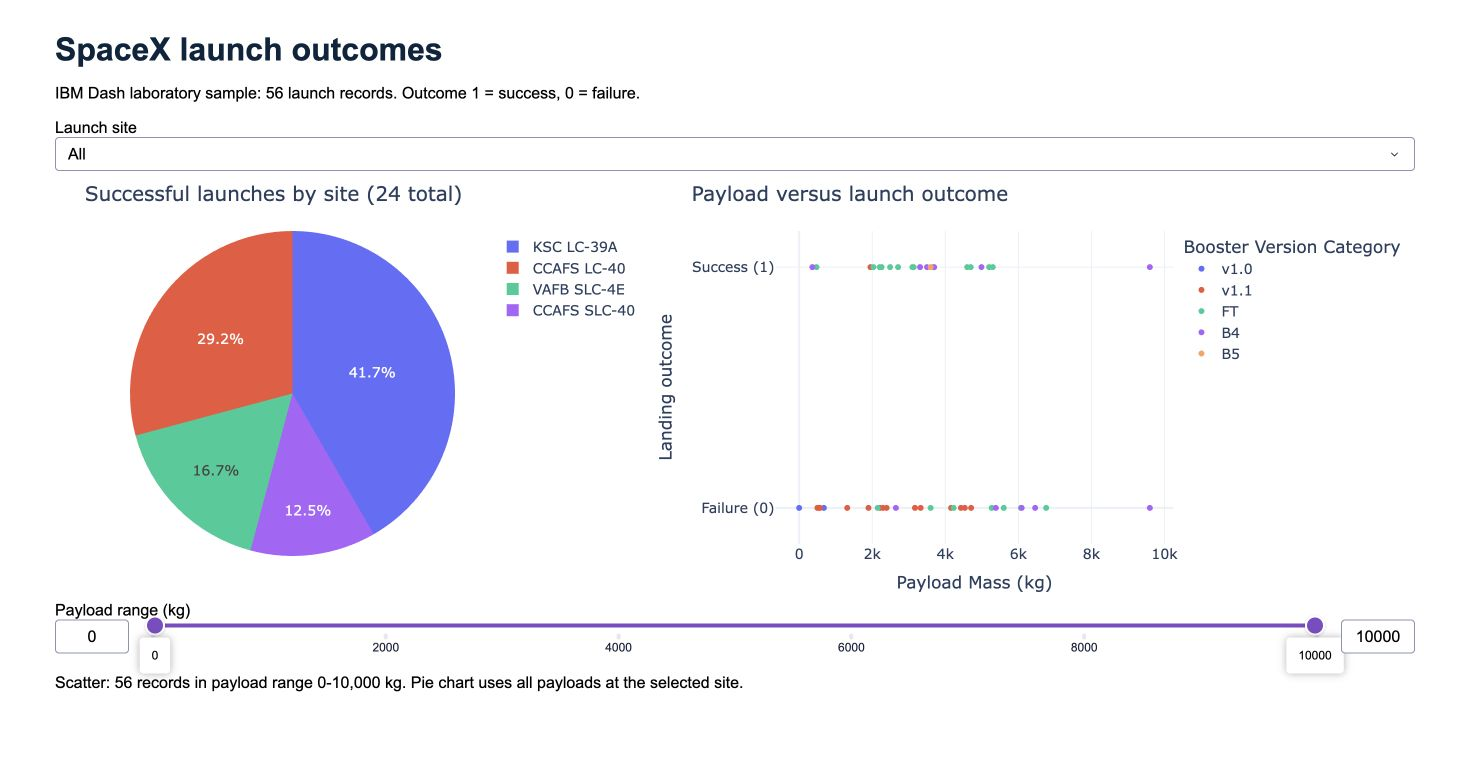

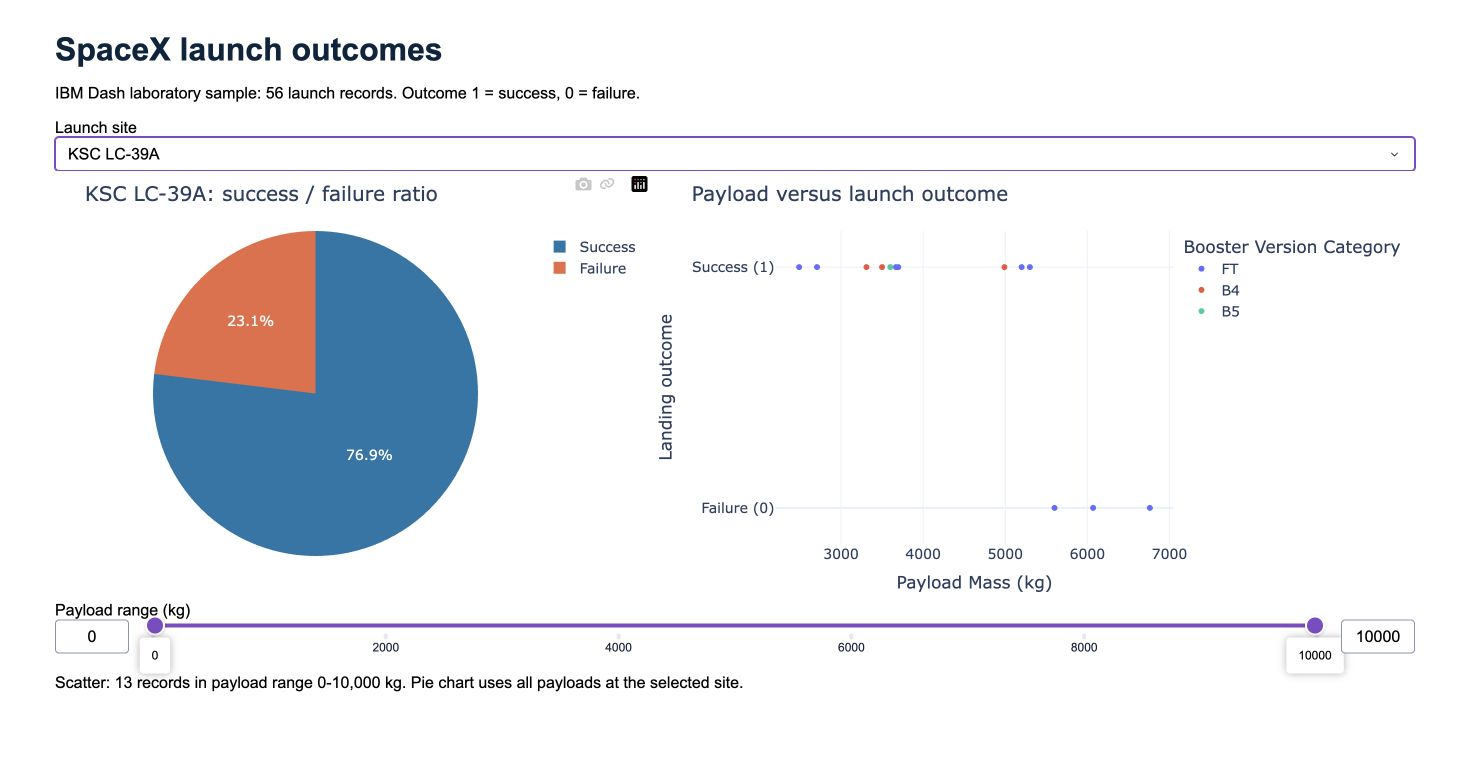

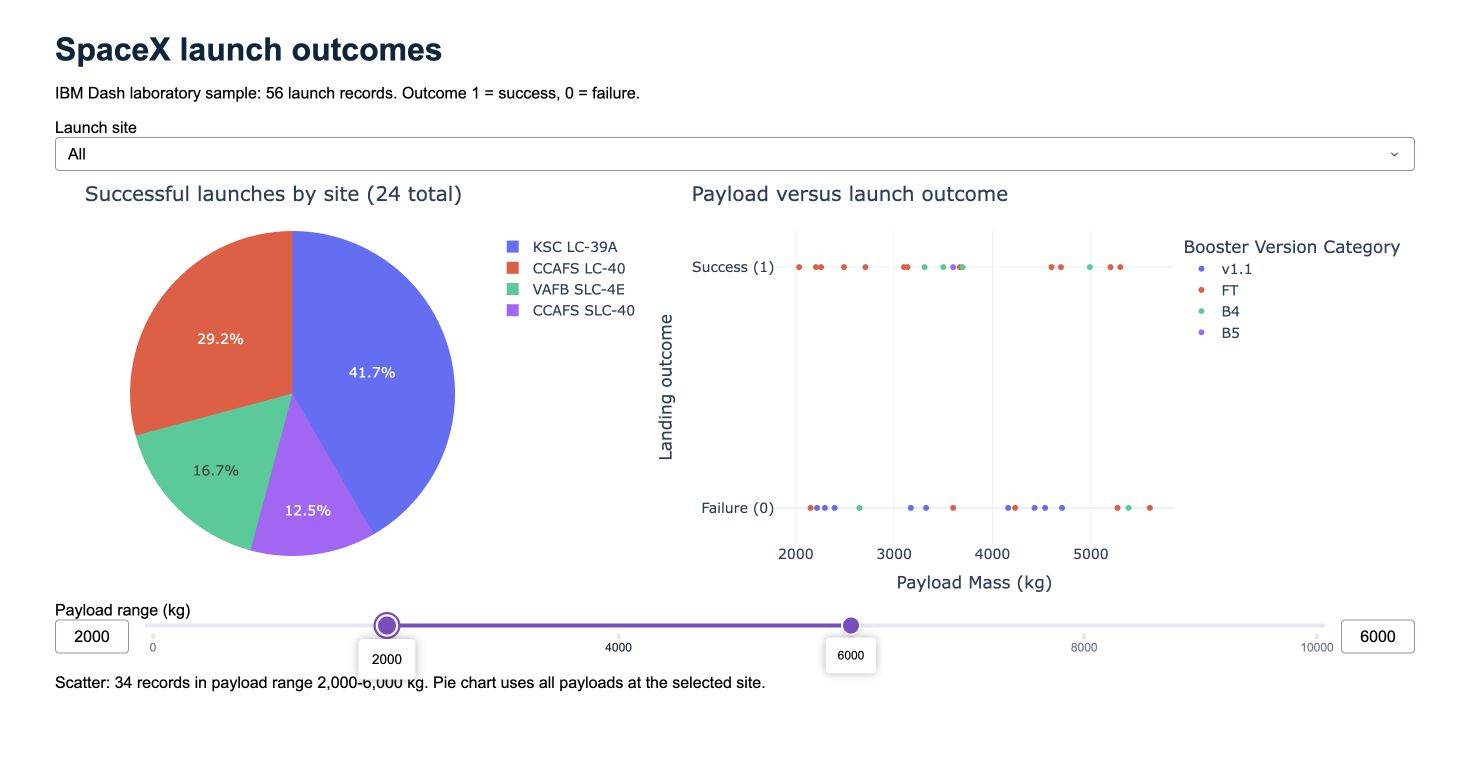

In [4]:
for name in ['dash_all.png','dash_ksc.png','dash_filtered.png']:
    display(Image(filename=str(root/'outputs/figures'/name)))